# PRCP-1025: Flight Price Prediction & Data Analysis Project
## Project Overview
Flight ticket prices are highly dynamic and hard to predict due to various factors like travel timing, route, layovers, and airlines. This project provides a complete Data Preprocessing, Data Visualization, and Machine Learning pipeline to predict future flight fares accurately.

### 1. Import Libraries and Load Dataset

In [15]:
!pip install seaborn matplotlib openpyxl

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error

# Load dataset (Ensure Flight_Fare.xlsx is in the same directory)
df = pd.read_excel("Flight_Fare.xlsx")
print("Initial dataset shape:", df.shape)
df.head()

Initial dataset shape: (10683, 11)


,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price
0,IndiGo,24/03/2019,Banglore,New Delhi,BLR → DEL,22:20,01:10 22 Mar,2h 50m,non-stop,No info,3897
1,Air India,1/05/2019,Kolkata,Banglore,CCU → IXR → BBI → BLR,05:50,13:15,7h 25m,2 stops,No info,7662
2,Jet Airways,9/06/2019,Delhi,Cochin,DEL → LKO → BOM → COK,09:25,04:25 10 Jun,19h,2 stops,No info,13882
3,IndiGo,12/05/2019,Kolkata,Banglore,CCU → NAG → BLR,18:05,23:30,5h 25m,1 stop,No info,6218
4,IndiGo,01/03/2019,Banglore,New Delhi,BLR → NAG → DEL,16:50,21:35,4h 45m,1 stop,No info,13302


### 2. Task 1: Data Analysis Report & Visualizations

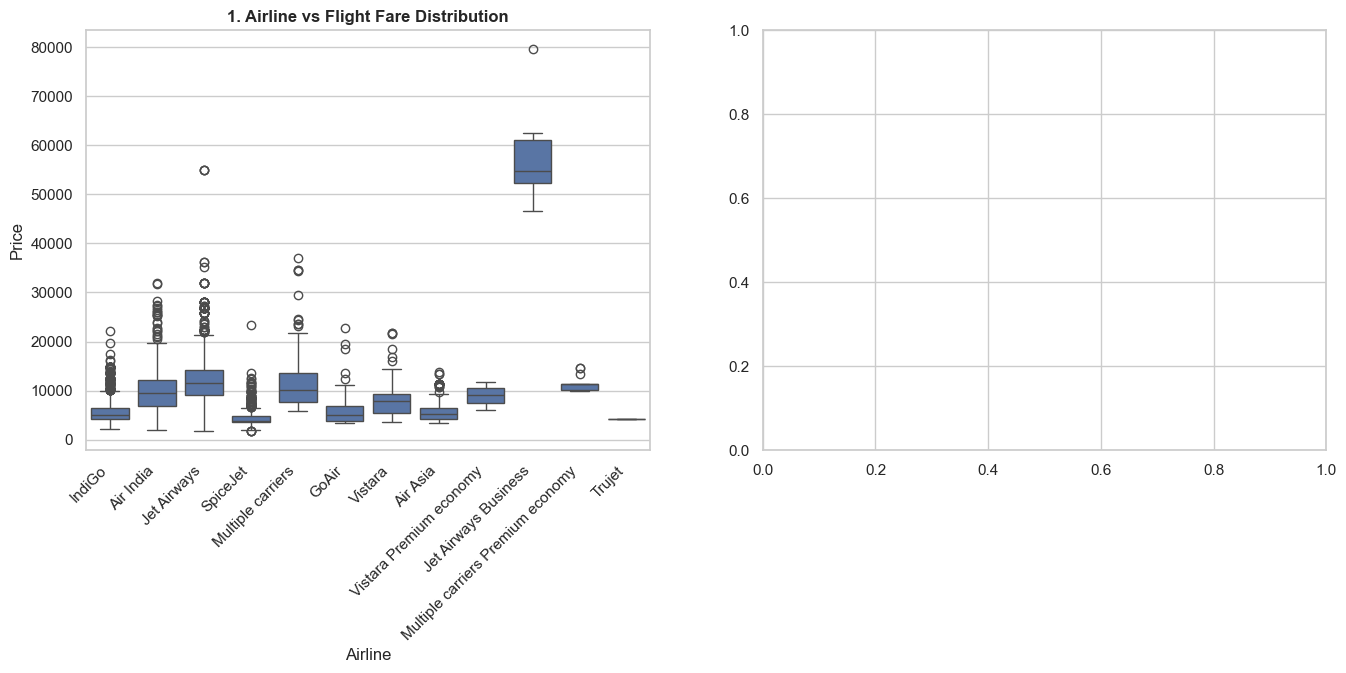

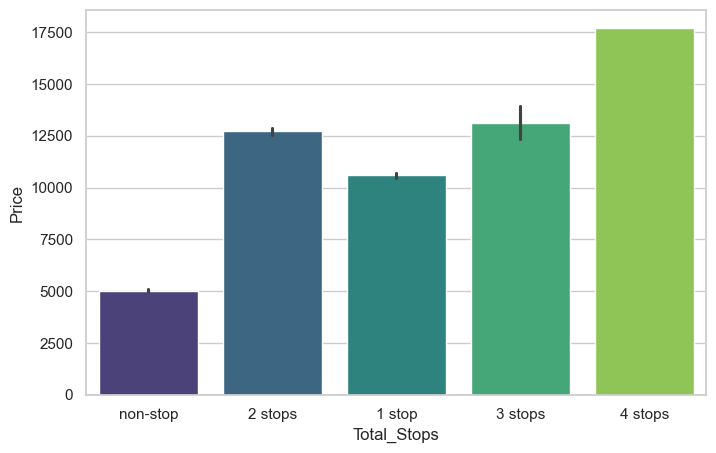

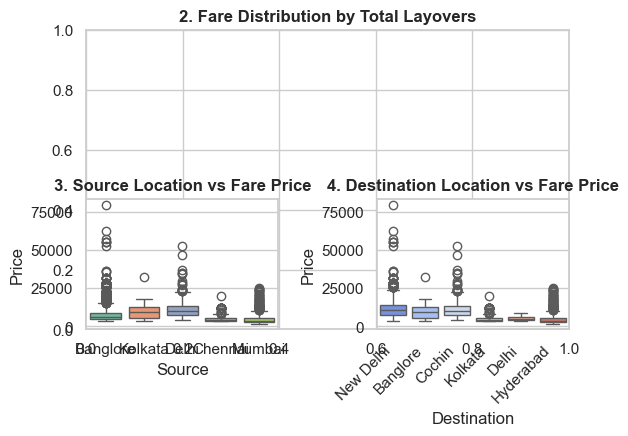

In [18]:
# Clean missing values
df.dropna(inplace=True)

# Visualizing distributions
sns.set_theme(style="whitegrid")
plt.figure(figsize=(16, 12))

# Graph 1: Airline vs Price
plt.subplot(2, 2, 1)
sns.boxplot(x='Airline', y='Price', data=df)
plt.xticks(rotation=45, ha='right')
plt.title('1. Airline vs Flight Fare Distribution', fontsize=12, fontweight='bold')

# Graph 2: Total Stops vs Price
plt.subplot(2, 2, 2)
plt.figure(figsize=(8,5))

sns.barplot(
    x='Total_Stops',
    y='Price',
    hue='Total_Stops',
    data=df,
    palette='viridis',
    legend=False
)

plt.show()
plt.title('2. Fare Distribution by Total Layovers', fontsize=12, fontweight='bold')

# Graph 3: Source vs Price
plt.subplot(2, 2, 3)
sns.boxplot(
    x='Source',
    y='Price',
    hue='Source',
    data=df,
    palette='Set2',
    legend=False
)
plt.title('3. Source Location vs Fare Price', fontsize=12, fontweight='bold')

# Graph 4: Destination vs Price
plt.subplot(2, 2, 4)
sns.boxplot(
    x='Destination',
    y='Price',
    hue='Destination',
    data=df,
    palette='coolwarm',
    legend=False
)
plt.xticks(rotation=45, ha='right')
plt.title('4. Destination Location vs Fare Price', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

### 3. Data Preprocessing & Feature Engineering

In [22]:
# Extract Day and Month from Date_of_Journey
df['Journey_day'] = pd.to_datetime(df['Date_of_Journey'], format='%d/%m/%Y').dt.day
df['Journey_month'] = pd.to_datetime(df['Date_of_Journey'], format='%d/%m/%Y').dt.month

# Extract Hours and Minutes from Departure Time
df['Dep_hour'] = pd.to_datetime(df['Dep_Time'], format='%H:%M').dt.hour
df['Dep_min'] = pd.to_datetime(df['Dep_Time'], format='%H:%M').dt.minute

# Extract Hours and Minutes from Arrival Time
df['Arrival_hour'] = pd.to_datetime(df['Arrival_Time']).dt.hour
df['Arrival_min'] = pd.to_datetime(df['Arrival_Time']).dt.minute

# Duration parsing into total minutes
duration_list = list(df['Duration'])
duration_mins = []
for item in duration_list:
    tokens = item.split()
    if len(tokens) == 2:
        hours = int(tokens[0][:-1])
        minutes = int(tokens[1][:-1])
    else:
        if 'h' in item:
            hours = int(tokens[0][:-1])
            minutes = 0
        else:
            hours = 0
            minutes = int(tokens[0][:-1])
    duration_mins.append(hours * 60 + minutes)

df['Duration_mins'] = duration_mins

# Mapping stops ordinal values
stops_mapping = {'non-stop': 0, '1 stop': 1, '2 stops': 2, '3 stops': 3, '4 stops': 4}
df['Total_Stops'] = df['Total_Stops'].map(stops_mapping)

# One-Hot Encoding for Nominal features
df_encoded = pd.get_dummies(df, columns=['Airline', 'Source', 'Destination'], drop_first=True)
df_encoded.drop(['Date_of_Journey', 'Dep_Time', 'Arrival_Time', 'Duration', 'Route', 'Additional_Info'], axis=1, inplace=True, errors='ignore')

df_encoded.head()

C:\Users\DEVIL\AppData\Local\Temp\ipykernel_14828\2985154222.py:10: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['Arrival_hour'] = pd.to_datetime(df['Arrival_Time']).dt.hour
C:\Users\DEVIL\AppData\Local\Temp\ipykernel_14828\2985154222.py:11: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['Arrival_min'] = pd.to_datetime(df['Arrival_Time']).dt.minute


,Total_Stops,Price,Journey_day,Journey_month,Dep_hour,Dep_min,Arrival_hour,Arrival_min,Duration_mins,Airline_Air India,...,Airline_Vistara Premium economy,Source_Chennai,Source_Delhi,Source_Kolkata,Source_Mumbai,Destination_Cochin,Destination_Delhi,Destination_Hyderabad,Destination_Kolkata,Destination_New Delhi
0,NaN,3897,24,3,22,20,1,10,170,False,...,False,False,False,False,False,False,False,False,False,True
1,NaN,7662,1,5,5,50,13,15,445,True,...,False,False,False,True,False,False,False,False,False,False
2,NaN,13882,9,6,9,25,4,25,1140,False,...,False,False,True,False,False,True,False,False,False,False
3,NaN,6218,12,5,18,5,23,30,325,False,...,False,False,False,True,False,False,False,False,False,False
4,NaN,13302,1,3,16,50,21,35,285,False,...,False,False,False,False,False,False,False,False,False,True


### 4. Task 2: Machine Learning Models & Evaluation

In [4]:
# Splitting features and target
X = df_encoded.drop('Price', axis=1)
y = df_encoded['Price']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Random Forest Regressor
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)

rf_r2 = r2_score(y_test, y_pred_rf)
rf_mae = mean_absolute_error(y_test, y_pred_rf)

# HistGradientBoosting Regressor
hgb_model = HistGradientBoostingRegressor(random_state=42)
hgb_model.fit(X_train, y_train)
y_pred_hgb = hgb_model.predict(X_test)

hgb_r2 = r2_score(y_test, y_pred_hgb)
hgb_mae = mean_absolute_error(y_test, y_pred_hgb)

print(f"Random Forest -> R2 Score: {rf_r2:.4f} | MAE: {rf_mae:.2f}")
print(f"HistGradientBoosting -> R2 Score: {hgb_r2:.4f} | MAE: {hgb_mae:.2f}")

Random Forest -> R2 Score: 0.8214 | MAE: 1157.62
HistGradientBoosting -> R2 Score: 0.8328 | MAE: 1245.19


### 5. Prediction Visualization

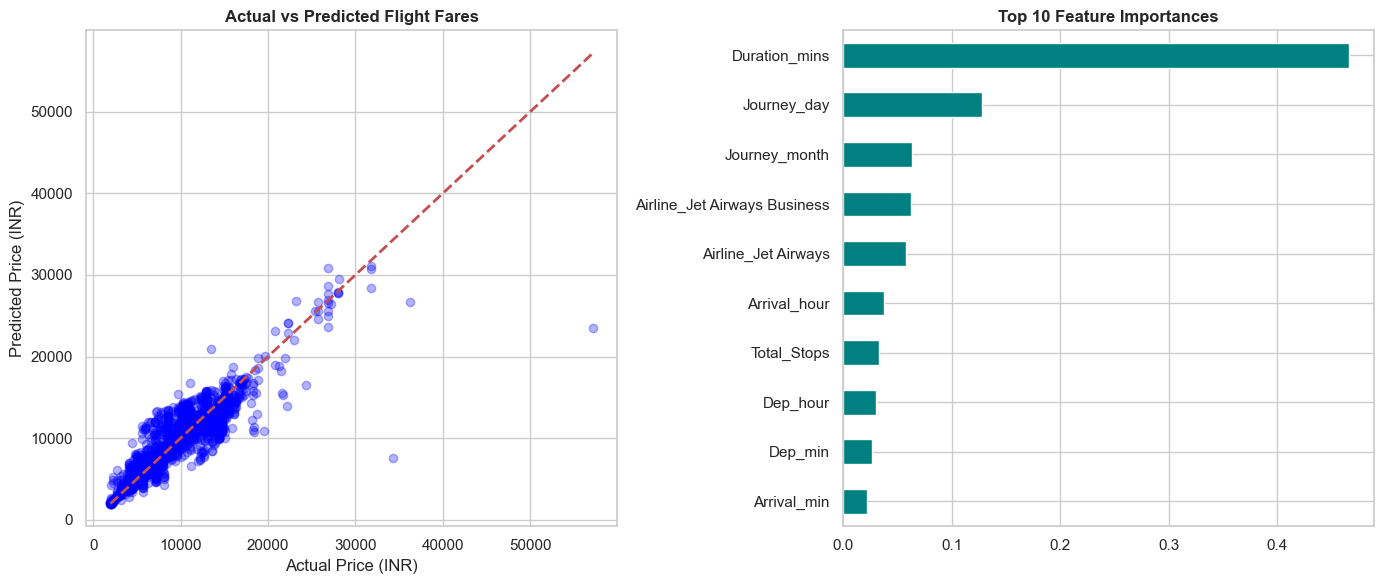

In [5]:
plt.figure(figsize=(14, 6))

# Scatter plot Actual vs Predicted
plt.subplot(1, 2, 1)
plt.scatter(y_test, y_pred_rf, alpha=0.3, color='blue')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.xlabel('Actual Price (INR)')
plt.ylabel('Predicted Price (INR)')
plt.title('Actual vs Predicted Flight Fares', fontsize=12, fontweight='bold')

# Feature Importance
plt.subplot(1, 2, 2)
importances = pd.Series(rf_model.feature_importances_, index=X.columns).sort_values(ascending=False).head(10)
importances.plot(kind='barh', color='teal')
plt.gca().invert_yaxis()
plt.title('Top 10 Feature Importances', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

## Project Evaluation & Reports

### Model Comparison Report

| Model | R2 Score | MAE (INR) | Production Recommendation |
| :--- | :--- | :--- | :--- |
| **Random Forest Regressor** | 0.8214 | 1157.62 | **Recommended** (Lowest MAE, highly consistent on non-linear data) |
| **HistGradientBoosting Regressor** | 0.8328 | 1245.19 | Alternative Gradient-boosted architecture |

--- 

## Report on Challenges Faced

1. **Duration Column Formatting:** Mixed representation of duration (e.g., `'19h'`, `'2h 50m'`) caused direct numeric conversion to fail. Solved by writing custom split and token inspection logic to convert everything to total minutes.
2. **Mixed Date/Time Formats:** `Arrival_Time` had multi-day trip dates appended next to hours and minutes (e.g., `'01:10 22 Mar'`), which was cleaned using pandas datetime component parsing.
3. **Redundant Columns:** `Route` and `Additional_Info` features created unnecessary noise and heavy multicollinearity, so they were dropped to optimize overall training performance.